# Phase 1 walkthrough — synthetic grid + LMP simulator

This notebook reads the outputs of `python -m src.run --phases 1` (it re-runs the pipeline if they are missing)
and walks through: (1) the two-town LMP example, (2) the toy Alberta network, (3) the synthetic inputs,
(4) hourly DC-OPF results and the sanity checks.

**Everything here is synthetic and illustrative.** DC power flow: no losses, no voltage, no reactive power.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
from src.config import load_config, data_dir
cfg = load_config()
if not (data_dir(cfg) / "phase1" / "lmp.parquet").exists():
    from src.run import phase1; phase1(cfg)
from src.run import load_result
res = load_result(data_dir(cfg) / "phase1")
copper = load_result(data_dir(cfg) / "phase1", "copper_")
inputs = pd.read_parquet(data_dir(cfg) / "phase1" / "inputs.parquet")

## 1. LMP in two towns
Town A has 300 MW of wind at \$0.5/MWh, town B has gas at \$50/MWh and 150 MW of load. The line A→B carries 100 MW at most.
The cheapest way to serve one *extra* MW in B is gas (the line is full) → LMP_B = \$50. One extra MW in A is served by
wind → LMP_A = \$0.5. If the line were 200 MW, wind serves everything and both towns pay \$0.5.

In [2]:
from tests.test_phase1 import two_town_cfg, frame
from src.simulate import solve_dispatch
for limit in (100, 200):
    r = solve_dispatch(two_town_cfg(limit), frame([150.0], [1.0]))
    print(f"line limit {limit:>3} MW -> LMP A={r.lmp.iloc[0]['A']:.2f}, B={r.lmp.iloc[0]['B']:.2f}, flow={r.flow.iloc[0]['A-B']:.0f} MW")

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
line limit 100 MW -> LMP A=0.50, B=50.00, flow=100 MW


line limit 200 MW -> LMP A=0.50, B=0.50, flow=150 MW


## 2. The toy network

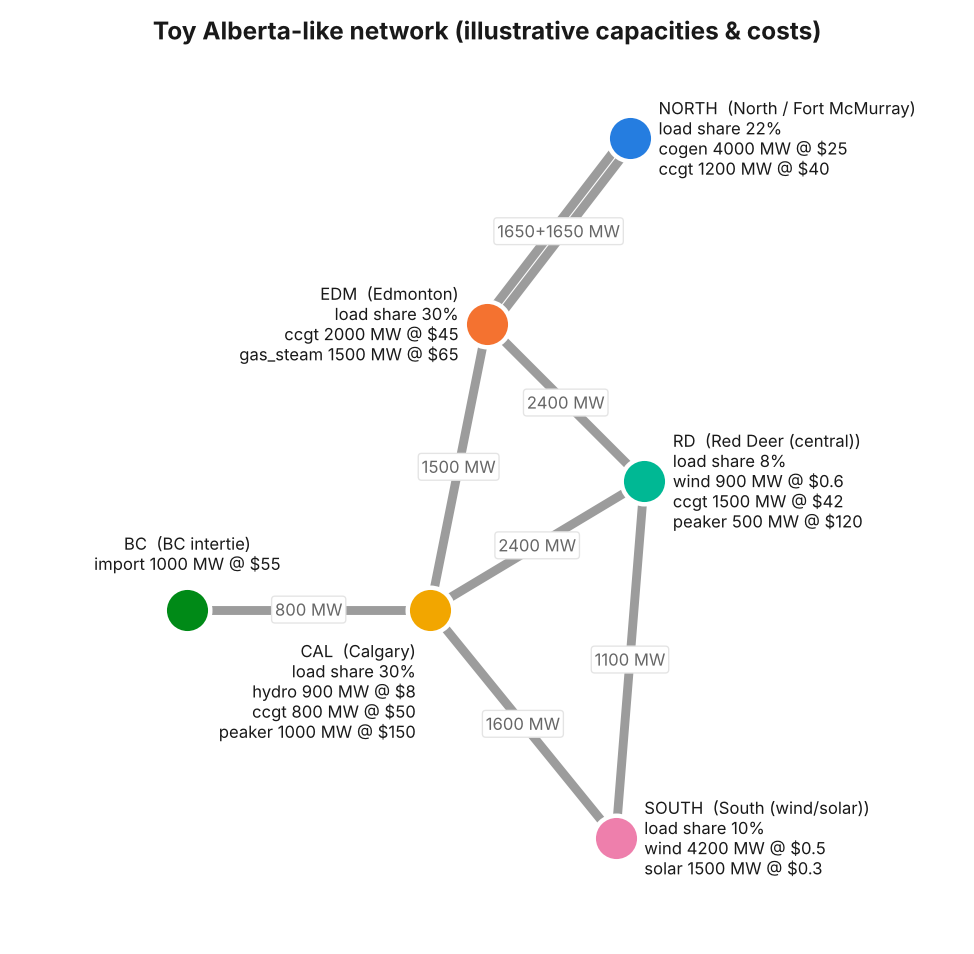

,bus,carrier,p_nom,marginal_cost
SOUTH_wind,SOUTH,wind,4200,0.5
SOUTH_solar,SOUTH,solar,1500,0.3
RD_wind,RD,wind,900,0.6
CAL_hydro,CAL,hydro,900,8.0
NORTH_cogen,NORTH,cogen,4000,25.0
NORTH_ccgt,NORTH,ccgt,1200,40.0
RD_ccgt,RD,ccgt,1500,42.0
EDM_ccgt,EDM,ccgt,2000,45.0
CAL_ccgt,CAL,ccgt,800,50.0
BC_import,BC,import,1000,55.0


In [3]:
display(Image("reports/figures/network.png", width=620))
pd.DataFrame(cfg["generators"]).T[["bus", "carrier", "p_nom", "marginal_cost"]]

## 3. Synthetic inputs (fixed seed, all parameters in `config.yaml`)

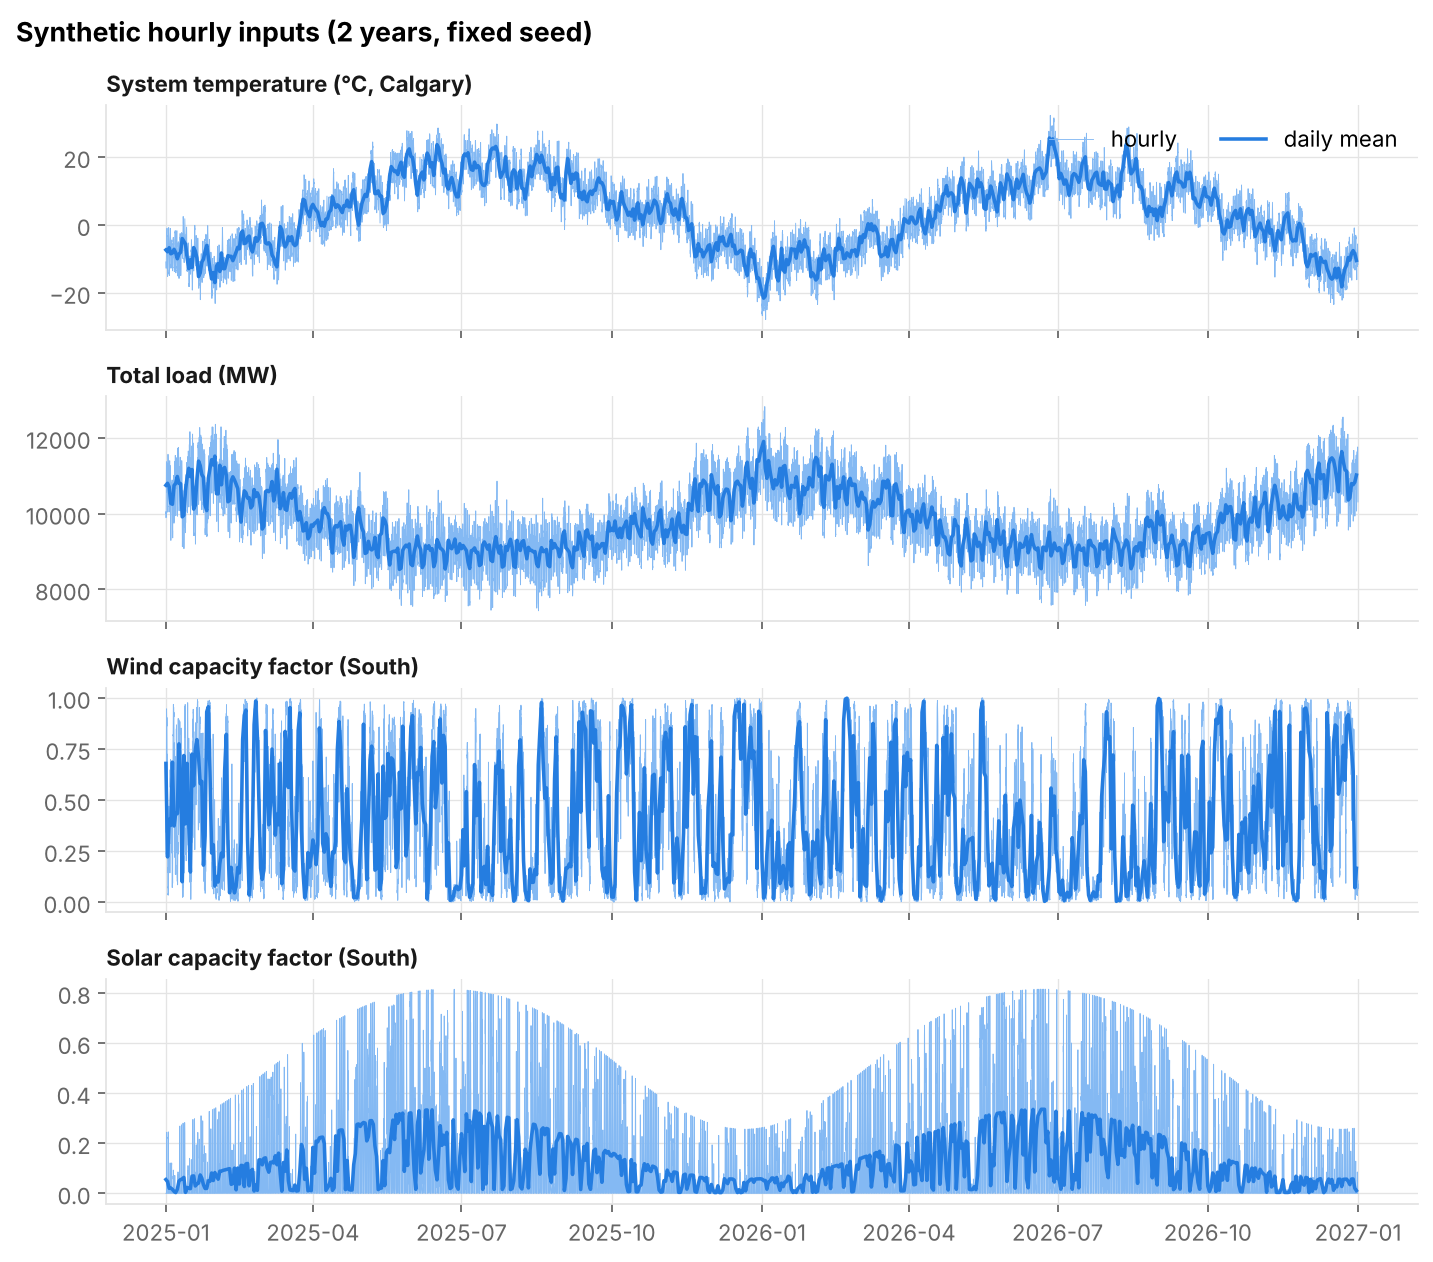

,mean,std,min,max
temp_CAL,3.32,10.99,-27.82,32.29
load_NORTH,2028.17,68.89,1816.31,2272.14
load_EDM,3005.41,331.57,2130.10,4139.87
load_RD,798.46,87.92,563.37,1089.58
load_CAL,2982.54,327.32,2135.01,4068.36
load_SOUTH,984.02,106.45,707.80,1323.81
cf_wind_south,0.39,0.33,0.00,1.00
cf_wind_central,0.38,0.32,0.00,1.00
cf_solar_south,0.12,0.20,0.00,0.82


In [4]:
display(Image("reports/figures/inputs_overview.png", width=800))
inputs.filter(regex="load_|cf_|temp_CAL").describe().T[["mean", "std", "min", "max"]].round(2)

## 4. Hourly DC-OPF results

In [5]:
display(Markdown(Path("reports/phase1_summary.md").read_text()))

# Phase 1 summary (auto-generated by `python -m src.run`)

* Hours simulated: **17,520**; DC-OPF wall time **42.9 s**
* Mean / peak total load: 9,799 / 12,826 MW
* Hours with ≥1 binding line: **27.0%** (target 10%–30%)
* Hours with load shedding: 0
* Mean |max−min| LMP spread across Alberta buses: 10.52 $/MWh (P95 49.5); without line limits: 5.46e-15

## Binding frequency by line

| line | share of hours at limit |
|---|---:|
| SOUTH-CAL | 22.1% |
| BC-CAL | 3.4% |
| EDM-NORTH-1 | 1.5% |
| EDM-NORTH-2 | 1.5% |
| SOUTH-RD | 0.0% |
| CAL-RD | 0.0% |
| RD-EDM | 0.0% |
| CAL-EDM | 0.0% |

## Mean LMP by bus ($/MWh)

| bus | with line limits | no line limits |
|---|---:|---:|
| NORTH | 45.26 | 44.51 |
| EDM | 45.31 | 44.51 |
| RD | 44.36 | 44.51 |
| CAL | 47.22 | 44.51 |
| SOUTH | 36.75 | 44.51 |
| BC | 46.85 | 44.51 |

## Energy share by technology (with line limits)

| carrier | share |
|---|---:|
| cogen | 40.8% |
| ccgt | 32.7% |
| wind | 19.2% |
| hydro | 4.9% |
| solar | 1.8% |
| import | 0.5% |
| gas_steam | 0.1% |
| peaker | 0.0% |

## Sanity checks

| check | result | details |
|---|---|---|
| copper_plate_single_price | PASS | max_price_spread_without_limits=1.42e-14 |
| independent_angle_dcopf_resolve | PASS | hours_checked=200, congested_hours_checked=100, max_abs_lmp_diff=2.34e-13, max_abs_flow_diff_mw=2.39e-11, hours_lmp_mismatch_gt_1e-3=[], share_hours_lmp_match=1 |
| physics | PASS | max_power_balance_error_mw=3.64e-12, max_kcl_error_mw=1.36e-12, max_overload_mw=0, min_price_separation_on_binding_lines=0 |
| congestion_target | PASS | share_hours_any_binding=0.27, target=[0.1, 0.3] |


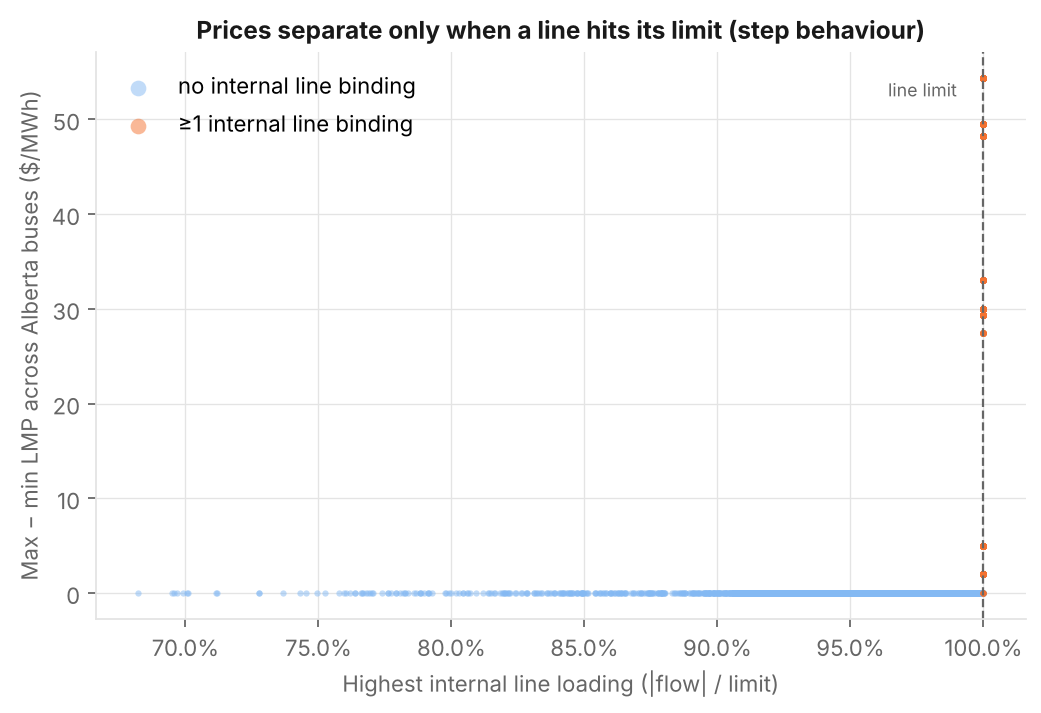

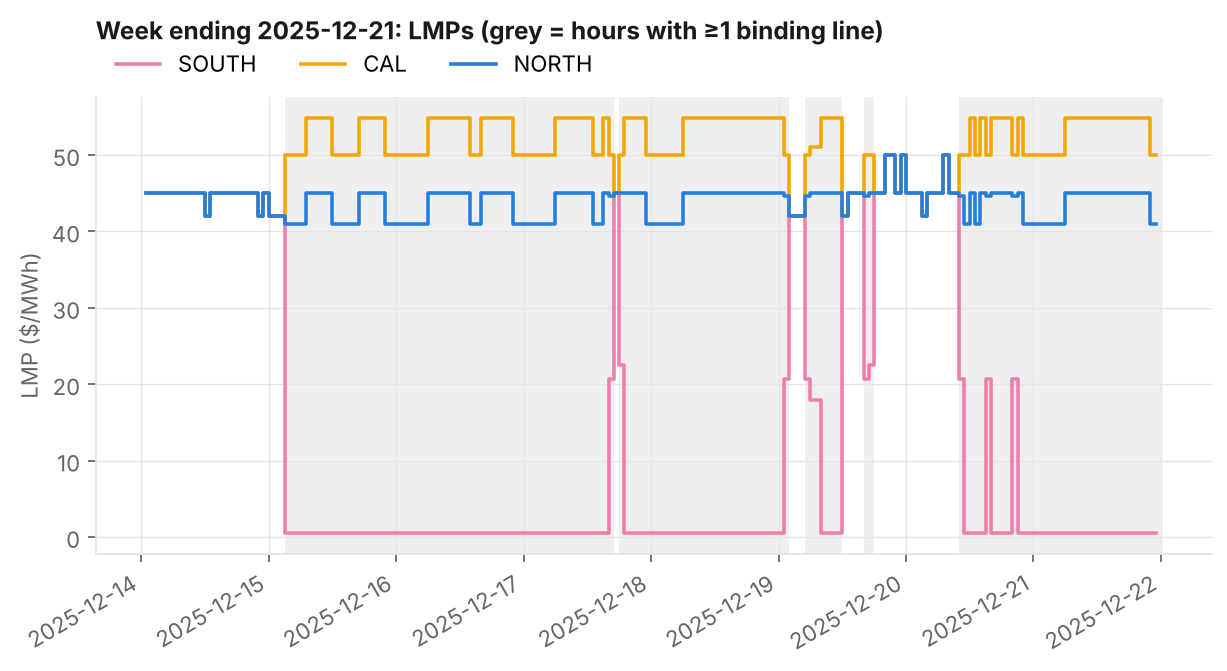

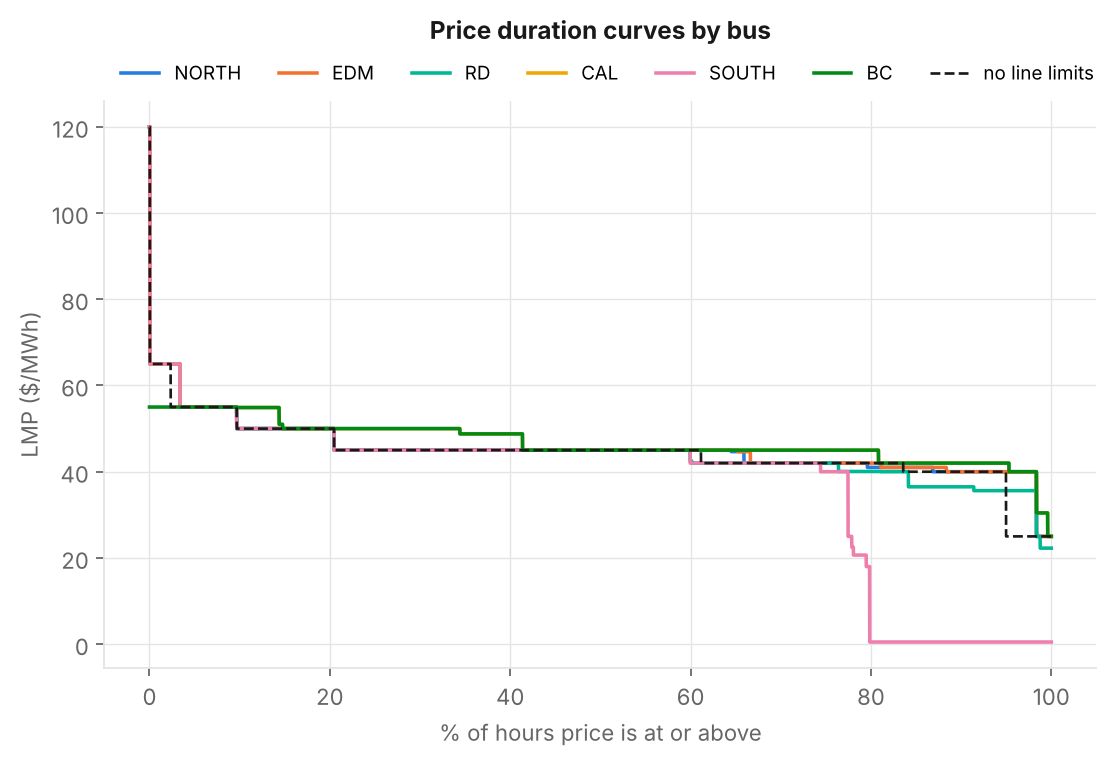

In [6]:
display(Image("reports/figures/spread_vs_loading.png", width=700))
display(Image("reports/figures/lmp_week.png", width=800))
display(Image("reports/figures/price_duration.png", width=700))

### LMP is a step function
Across 17,520 hours each bus takes only ~10–13 distinct price values: the price is set by whichever offer is marginal,
and jumps when a line hits its limit. This matters for the Phase 3 surrogates.

In [7]:
res.lmp.round(2).apply(lambda s: s.value_counts().head(5)).fillna(0).astype(int)

,NORTH,EDM,RD,CAL,SOUTH,BC
0.50,0,0,0,0,3530,0
35.61,0,0,1217,0,0,0
36.50,0,0,1271,0,0,0
40.00,2014,1751,0,0,0,0
41.00,1271,1271,0,0,0,0
42.00,2397,2535,2851,2535,2535,2535
45.00,7713,7838,6915,6915,6915,6915
48.78,0,0,0,1217,0,1217
50.00,1892,1892,1892,3444,1892,3444
55.00,0,0,0,1104,1104,1694
